In [1]:
import os
import sys

# Forcer les chemins Python
os.environ["PYSPARK_PYTHON"] = "/opt/conda/bin/python"
os.environ["PYSPARK_DRIVER_PYTHON"] = "/opt/conda/bin/python"

# Verifier les versions
print(f"Current Python: {sys.executable}")
print(f"Python version: {sys.version}")

# Verifier que /opt/conda/bin/python existe
import subprocess
try:
    result = subprocess.run(["/opt/conda/bin/python", "--version"], capture_output=True, text=True)
    print(f"/opt/conda/bin/python version: {result.stderr}")
except Exception as e:
    print(f"Error: {e}")
    print("Trying to find correct python path")
    result = subprocess.run(["which", "python"], capture_output=True, text=True)
    print(f"which python: {result.stdout}")

Current Python: /opt/conda/bin/python
Python version: 3.11.6 | packaged by conda-forge | (main, Oct  3 2023, 10:40:35) [GCC 12.3.0]
/opt/conda/bin/python version: 


In [9]:
import sys
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

spark = SparkSession.builder \
    .appName("TestPythonVersion") \
    .config("spark.hadoop.fs.s3a.endpoint", "http://100.104.4.32:9000") \
    .config("spark.hadoop.fs.s3a.access.key", "minioadmin") \
    .config("spark.hadoop.fs.s3a.secret.key", "minioadmin123") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .getOrCreate()

def get_python_version(x):
    import sys
    return sys.version

get_version_udf = F.udf(get_python_version, F.StringType())

df_test = spark.range(1).withColumn("worker_version", get_version_udf(F.col("id")))
df_test.show(truncate=False)

print("Driver version:", sys.version)

spark.stop()

+---+-----------------------------------------------------------------------------+
|id |worker_version                                                               |
+---+-----------------------------------------------------------------------------+
|0  |3.11.6 | packaged by conda-forge | (main, Oct  3 2023, 10:40:35) [GCC 12.3.0]|
+---+-----------------------------------------------------------------------------+

Driver version: 3.11.6 | packaged by conda-forge | (main, Oct  3 2023, 10:40:35) [GCC 12.3.0]


In [1]:
!pip install kafka-python boto3 pyarrow pandas

In [2]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
import sys

spark = SparkSession.builder \
    .appName("TaaSim-ML-Pipeline") \
    .config("spark.hadoop.fs.s3a.endpoint", "http://100.104.4.32:9000") \
    .config("spark.hadoop.fs.s3a.access.key", "minioadmin") \
    .config("spark.hadoop.fs.s3a.secret.key", "minioadmin123") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .config("spark.pyspark.python", sys.executable) \
    .config("spark.pyspark.driver.python", sys.executable) \
    .getOrCreate()

print("Spark session created")
print("Spark version:", spark.version)
print("Python version:", sys.version)

Spark session created
Spark version: 3.5.0
Python version: 3.11.6 | packaged by conda-forge | (main, Oct  3 2023, 10:40:35) [GCC 12.3.0]


In [3]:
# Lister le contenu du dossier pour confirmer
import boto3
from botocore.client import Config

s3 = boto3.client(
    "s3",
    endpoint_url="http://100.104.4.32:9000",
    aws_access_key_id="minioadmin",
    aws_secret_access_key="minioadmin123",
    config=Config(signature_version="s3v4"),
)

result = s3.list_objects_v2(Bucket="curated", Prefix="demand-by-zone-casa/")
if 'Contents' in result:
    print(" Dossier demand-by-zone-casa/ trouvé")
    for obj in result['Contents'][:5]:
        print(f"   - {obj['Key']}")
else:
    print(" Dossier non trouvé. Vérifie le chemin.")

 Dossier demand-by-zone-casa/ trouvé
   - demand-by-zone-casa/_SUCCESS
   - demand-by-zone-casa/zone_id=0/part-00000-fcfcd6e3-6f7e-43b4-8177-e465f5fa0cf3.c000.snappy.parquet
   - demand-by-zone-casa/zone_id=1/part-00000-fcfcd6e3-6f7e-43b4-8177-e465f5fa0cf3.c000.snappy.parquet
   - demand-by-zone-casa/zone_id=10/part-00000-fcfcd6e3-6f7e-43b4-8177-e465f5fa0cf3.c000.snappy.parquet
   - demand-by-zone-casa/zone_id=11/part-00000-fcfcd6e3-6f7e-43b4-8177-e465f5fa0cf3.c000.snappy.parquet


In [24]:
!pip install pyarrow -q

In [4]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F

# Créer la session Spark
spark = SparkSession.builder \
    .appName("TaaSim-ML-Pipeline") \
    .config("spark.hadoop.fs.s3a.endpoint", "http://100.104.4.32:9000") \
    .config("spark.hadoop.fs.s3a.access.key", "minioadmin") \
    .config("spark.hadoop.fs.s3a.secret.key", "minioadmin123") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .getOrCreate()

print(" Spark démarré")

# Test de lecture directe
demand_df = spark.read.parquet("s3a://curated/demand-by-zone-casa/")
demand_df.printSchema()
demand_df.show(5)

 Spark démarré
root
 |-- casa_zone: string (nullable = true)
 |-- demand_level: string (nullable = true)
 |-- hour: integer (nullable = true)
 |-- nb_trips: long (nullable = true)
 |-- avg_distance_km: double (nullable = true)
 |-- avg_fare_mad: double (nullable = true)
 |-- zone_id: integer (nullable = true)

+-----------+------------+----+--------+------------------+------------------+-------+
|  casa_zone|demand_level|hour|nb_trips|   avg_distance_km|      avg_fare_mad|zone_id|
+-----------+------------+----+--------+------------------+------------------+-------+
|Hay Hassani|      medium|   0|     428| 7.011856588785047| 241.8964953271028|      6|
|Hay Hassani|      medium|   1|     246| 7.514553252032518|257.79999999999995|      6|
|Hay Hassani|      medium|   2|     251|6.9814574103585665|254.87768924302787|      6|
|Hay Hassani|      medium|   3|     241|  9.77964887966805| 292.8821576763486|      6|
|Hay Hassani|      medium|   4|     428|12.885608831775702| 321.9866822429907| 

In [5]:
# Lire les données brutes NYC (un ou plusieurs mois)
nyc_df = spark.read.parquet("s3a://raw/nyc-tlc/*.parquet")

In [6]:
from pyspark.sql import functions as F
from pyspark.sql.functions import col, hour, dayofweek, to_date

nyc_clean = nyc_df.filter(
    (col("trip_distance") > 0) & (col("trip_distance") < 100) &
    (col("fare_amount") > 0) & (col("fare_amount") < 500) &
    (col("passenger_count") > 0) & (col("passenger_count") <= 6) &
    (col("tpep_pickup_datetime").isNotNull())
)

nyc_transformed = nyc_clean \
    .withColumn("date", to_date("tpep_pickup_datetime")) \
    .withColumn("hour", hour("tpep_pickup_datetime")) \
    .withColumn("distance_km", col("trip_distance") * 1.609) \
    .withColumn("fare_mad", col("fare_amount") * 10)

In [7]:
# Charger le mapping zone_id
zone_mapping_df = spark.read.option("header", "true").csv("s3a://curated/zone_mapping_casa.csv")

nyc_with_zone = nyc_transformed.join(zone_mapping_df, on="PULocationID", how="left")
nyc_with_zone = nyc_with_zone.filter(col("zone_id").isNotNull())

In [21]:
demand_with_date = nyc_with_zone.groupBy("date", "zone_id", "casa_zone", "demand_level", "hour") \
    .agg(
        F.count("*").alias("nb_trips"),
        F.avg("distance_km").alias("avg_distance_km"),
        F.avg("fare_mad").alias("avg_fare_mad")
    ) \
    .orderBy("date", "zone_id", "hour")

print(f"Nombre de lignes avec date : {demand_with_date.count():,}")
demand_with_date.show(10)

Nombre de lignes avec date : 8,708
+----------+-------+---------+------------+----+--------+------------------+------------------+
|      date|zone_id|casa_zone|demand_level|hour|nb_trips|   avg_distance_km|      avg_fare_mad|
+----------+-------+---------+------------+----+--------+------------------+------------------+
|2025-12-31|      0|   Maarif|        high|  23|       1|           0.69187|             149.0|
|2025-12-31|     11|Bernoussi|         low|  23|       2|           2.96056|             117.5|
|2025-12-31|      7|    Sbata|      medium|  23|       2|32.300675000000005|            1186.0|
|2026-01-01|      0|   Maarif|        high|   0|    1533| 4.027275570776262|  177.224983692107|
|2026-01-01|      0|   Maarif|        high|   1|    1442| 3.981951414701803|167.10194174757282|
|2026-01-01|      0|   Maarif|        high|   2|    1171| 4.335684773697693|172.25704526046115|
|2026-01-01|      0|   Maarif|        high|   3|     747|4.9912386211512745|178.32998661311913|
|2026

In [8]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.functions import col, hour, dayofweek, to_date
import boto3
from botocore.client import Config

spark = SparkSession.builder \
    .appName("TaaSim-ML-Pipeline") \
    .config("spark.hadoop.fs.s3a.endpoint", "http://100.104.4.32:9000") \
    .config("spark.hadoop.fs.s3a.access.key", "minioadmin") \
    .config("spark.hadoop.fs.s3a.secret.key", "minioadmin123") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .getOrCreate()

print("Spark session created")
print("Spark version:", spark.version)

nyc_df = spark.read.parquet("s3a://raw/nyc-tlc/*.parquet")

print("Raw data loaded")
print(f"Total rows: {nyc_df.count():,}")

nyc_clean = nyc_df.filter(
    (col("trip_distance") > 0) & (col("trip_distance") < 100) &
    (col("fare_amount") > 0) & (col("fare_amount") < 500) &
    (col("passenger_count") > 0) & (col("passenger_count") <= 6) &
    (col("tpep_pickup_datetime").isNotNull())
)

print(f"Rows after cleaning: {nyc_clean.count():,}")

nyc_transformed = nyc_clean \
    .withColumn("date", to_date("tpep_pickup_datetime")) \
    .withColumn("hour", hour("tpep_pickup_datetime")) \
    .withColumn("distance_km", col("trip_distance") * 1.609) \
    .withColumn("fare_mad", col("fare_amount") * 10)

print("Columns added: date, hour, distance_km, fare_mad")

zone_mapping_df = spark.read.option("header", "true").csv("s3a://curated/zone_mapping_casa.csv")

print("Zone mapping loaded")
zone_mapping_df.show(5)

nyc_with_zone = nyc_transformed.join(zone_mapping_df, on="PULocationID", how="left")
nyc_with_zone = nyc_with_zone.filter(col("zone_id").isNotNull())

print(f"Rows after zone join: {nyc_with_zone.count():,}")

demand_with_date = nyc_with_zone.groupBy("date", "zone_id", "casa_zone", "demand_level", "hour") \
    .agg(
        F.count("*").alias("nb_trips"),
        F.avg("distance_km").alias("avg_distance_km"),
        F.avg("fare_mad").alias("avg_fare_mad")
    ) \
    .orderBy("date", "zone_id", "hour")

print(f"Aggregated rows: {demand_with_date.count():,}")
demand_with_date.show(10)

demand_with_date.write.mode("overwrite").partitionBy("zone_id").parquet("s3a://curated/demand_with_date/")
print("Data with date saved to s3a://curated/demand_with_date/")

test_read = spark.read.parquet("s3a://curated/demand_with_date/")
print(f"Verification - rows: {test_read.count():,}")
test_read.show(5)

Spark session created
Spark version: 3.5.0
Raw data loaded
Total rows: 3,724,889
Rows after cleaning: 2,551,788
Columns added: date, hour, distance_km, fare_mad
Zone mapping loaded
+------------+-------+-----------+------------+
|PULocationID|zone_id|  casa_zone|demand_level|
+------------+-------+-----------+------------+
|         148|     11|  Bernoussi|         low|
|         243|      6|Hay Hassani|      medium|
|          31|      1|   Ain Diab|        high|
|         137|     11|  Bernoussi|         low|
|          85|      6|Hay Hassani|      medium|
+------------+-------+-----------+------------+
only showing top 5 rows

Rows after zone join: 2,551,788
Aggregated rows: 8,708
+----------+-------+---------+------------+----+--------+------------------+------------------+
|      date|zone_id|casa_zone|demand_level|hour|nb_trips|   avg_distance_km|      avg_fare_mad|
+----------+-------+---------+------------+----+--------+------------------+------------------+
|2025-12-31|      0

In [9]:
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.functions import col, hour, dayofweek, to_date
import boto3
from botocore.client import Config

spark = SparkSession.builder \
    .appName("TaaSim-ML-Pipeline") \
    .config("spark.hadoop.fs.s3a.endpoint", "http://100.104.4.32:9000") \
    .config("spark.hadoop.fs.s3a.access.key", "minioadmin") \
    .config("spark.hadoop.fs.s3a.secret.key", "minioadmin123") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .getOrCreate()

print("Spark session created")
print("Spark version:", spark.version)

s3 = boto3.client(
    "s3",
    endpoint_url="http://100.104.4.32:9000",
    aws_access_key_id="minioadmin",
    aws_secret_access_key="minioadmin123",
    config=Config(signature_version="s3v4"),
    region_name="us-east-1"
)

buckets = s3.list_buckets()
print("Existing buckets:")
for b in buckets['Buckets']:
    print(f"  - {b['Name']}")

demand_with_date = spark.read.parquet("s3a://curated/demand_with_date/")
demand_with_date.printSchema()
demand_with_date.show(10)

Spark session created
Spark version: 3.5.0
Existing buckets:
  - curated
  - kafka-archive
  - raw
  - simulated
root
 |-- date: date (nullable = true)
 |-- casa_zone: string (nullable = true)
 |-- demand_level: string (nullable = true)
 |-- hour: integer (nullable = true)
 |-- nb_trips: long (nullable = true)
 |-- avg_distance_km: double (nullable = true)
 |-- avg_fare_mad: double (nullable = true)
 |-- zone_id: integer (nullable = true)

+----------+---------+------------+----+--------+------------------+------------------+-------+
|      date|casa_zone|demand_level|hour|nb_trips|   avg_distance_km|      avg_fare_mad|zone_id|
+----------+---------+------------+----+--------+------------------+------------------+-------+
|2025-12-31|Bernoussi|         low|  23|       2|           2.96056|             117.5|     11|
|2026-01-01|Bernoussi|         low|   7|     204|5.4027696078431395| 165.9436274509804|     11|
|2026-01-01|Bernoussi|         low|  16|    1148|3.6795923867595826|150.4015

In [11]:
import sys
from pyspark.sql import SparkSession
from pyspark.sql import functions as F
from pyspark.sql.window import Window
from pyspark.ml.feature import VectorAssembler, StandardScaler
from pyspark.ml.regression import GBTRegressor
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml import Pipeline
from pyspark.sql.types import DoubleType

print("Python version:", sys.version)

spark = SparkSession.builder \
    .appName("TaaSim-ML-Pipeline") \
    .config("spark.hadoop.fs.s3a.endpoint", "http://100.104.4.32:9000") \
    .config("spark.hadoop.fs.s3a.access.key", "minioadmin") \
    .config("spark.hadoop.fs.s3a.secret.key", "minioadmin123") \
    .config("spark.hadoop.fs.s3a.path.style.access", "true") \
    .config("spark.hadoop.fs.s3a.impl", "org.apache.hadoop.fs.s3a.S3AFileSystem") \
    .getOrCreate()

print("Spark session created")

demand_df = spark.read.parquet("s3a://curated/demand_with_date/")
print(f"Data loaded. Rows: {demand_df.count():,}")

demand_df = demand_df \
    .withColumn("hour_of_day", F.col("hour")) \
    .withColumn("day_of_week", F.dayofweek(F.col("date"))) \
    .withColumn("is_weekend", F.when(F.col("day_of_week").isin([1, 7]), 1).otherwise(0)) \
    .withColumn("is_friday", F.when(F.col("day_of_week") == 6, 1).otherwise(0))

zone_ref = spark.createDataFrame([
    (0, 150000, 0, 1, 0),
    (1, 80000, 0, 1, 0),
    (2, 120000, 1, 0, 0),
    (3, 50000, 0, 0, 1),
    (4, 200000, 0, 1, 0),
    (5, 100000, 1, 0, 0),
    (6, 180000, 1, 0, 0),
    (7, 90000, 1, 0, 0),
    (8, 110000, 1, 0, 0),
    (9, 70000, 1, 0, 0),
    (10, 60000, 1, 0, 0),
    (11, 50000, 1, 0, 0),
    (12, 250000, 1, 0, 0),
    (13, 80000, 1, 0, 0),
    (14, 95000, 0, 1, 0),
    (15, 40000, 1, 0, 0),
], ["zone_id", "zone_population", "zone_type_residential", "zone_type_commercial", "zone_type_transit_hub"])

demand_df = demand_df.join(zone_ref, on="zone_id", how="left")

window_spec_1d = Window.partitionBy("zone_id").orderBy("date")

demand_df = demand_df \
    .withColumn("demand_lag_1d", F.lag("nb_trips", 1).over(window_spec_1d)) \
    .withColumn("demand_lag_7d", F.lag("nb_trips", 7).over(window_spec_1d))

demand_df = demand_df.filter(
    F.col("demand_lag_1d").isNotNull() &
    F.col("demand_lag_7d").isNotNull()
)

print(f"Rows after lag features: {demand_df.count():,}")

demand_df = demand_df.withColumn("nb_trips", F.col("nb_trips").cast(DoubleType()))
demand_df = demand_df.withColumn("demand_lag_1d", F.col("demand_lag_1d").cast(DoubleType()))
demand_df = demand_df.withColumn("demand_lag_7d", F.col("demand_lag_7d").cast(DoubleType()))

feature_cols = ["hour_of_day", "day_of_week", "is_weekend", "is_friday", 
                "zone_population", "zone_type_residential", 
                "zone_type_commercial", "zone_type_transit_hub",
                "demand_lag_1d", "demand_lag_7d"]

assembler = VectorAssembler(inputCols=feature_cols, outputCol="features")

gbt = GBTRegressor(
    featuresCol="features", 
    labelCol="nb_trips", 
    maxDepth=5, 
    maxIter=50, 
    seed=42
)

pipeline = Pipeline(stages=[assembler, gbt])

train_df, test_df = demand_df.randomSplit([0.8, 0.2], seed=42)

print(f"Training set: {train_df.count():,} rows")
print(f"Test set: {test_df.count():,} rows")

model = pipeline.fit(train_df)

predictions = model.transform(test_df)

evaluator_rmse = RegressionEvaluator(labelCol="nb_trips", predictionCol="prediction", metricName="rmse")
evaluator_mae = RegressionEvaluator(labelCol="nb_trips", predictionCol="prediction", metricName="mae")

rmse = evaluator_rmse.evaluate(predictions)
mae = evaluator_mae.evaluate(predictions)

print(f"GBT Model RMSE: {rmse:.2f}")
print(f"GBT Model MAE: {mae:.2f}")

baseline_predictions = test_df.withColumn("prediction", F.col("demand_lag_7d").cast(DoubleType()))
baseline_rmse = evaluator_rmse.evaluate(baseline_predictions)
baseline_mae = evaluator_mae.evaluate(baseline_predictions)

print(f"Baseline (7-day lag) RMSE: {baseline_rmse:.2f}")
print(f"Baseline (7-day lag) MAE: {baseline_mae:.2f}")

if rmse < baseline_rmse:
    print("SUCCESS: Model beats baseline")
else:
    print(f"Model does not beat baseline yet. Improvement needed: {(baseline_rmse - rmse) / baseline_rmse * 100:.2f}%")

comparison_by_zone = predictions.groupBy("zone_id").agg(
    F.sqrt(F.avg(F.pow(F.col("nb_trips") - F.col("prediction"), 2))).alias("model_rmse"),
    F.sqrt(F.avg(F.pow(F.col("nb_trips") - F.col("demand_lag_7d"), 2))).alias("baseline_rmse")
).orderBy("zone_id")

print("\nComparison by zone:")
comparison_by_zone.show(16)

gbt_model = model.stages[-1]
feature_importance = gbt_model.featureImportances
features_with_importance = [(feature_cols[i], float(feature_importance[i])) for i in range(len(feature_cols))]
features_with_importance.sort(key=lambda x: x[1], reverse=True)

print("\nTop 5 most important features:")
for feat, imp in features_with_importance[:5]:
    print(f"  - {feat}: {imp:.4f}")

model.write().overwrite().save("s3a://curated/demand_model_v1/")
print("\nModel saved to s3a://curated/demand_model_v1/")

print("\nPipeline completed successfully")

Python version: 3.11.6 | packaged by conda-forge | (main, Oct  3 2023, 10:40:35) [GCC 12.3.0]
Spark session created
Data loaded. Rows: 8,708
Rows after lag features: 8,607
Training set: 6,953 rows
Test set: 1,654 rows
GBT Model RMSE: 157.36
GBT Model MAE: 70.50
Baseline (7-day lag) RMSE: 435.79
Baseline (7-day lag) MAE: 202.96
SUCCESS: Model beats baseline

Comparison by zone:
+-------+------------------+-------------------+
|zone_id|        model_rmse|      baseline_rmse|
+-------+------------------+-------------------+
|      0| 317.5330158532442| 1084.3104502596907|
|      1|12.279389597485412| 15.065412927187447|
|      2| 93.81442544486623| 219.96710191736838|
|      3| 256.7522285931805|  645.0010546845778|
|      6| 30.22199942582485|  54.06522552538842|
|      7|116.04671574352402|  270.4905404082204|
|      8| 17.45918905682481|                0.0|
|      9| 8.474811844409412|   9.20038362371534|
|     10|10.168297871724135|0.22360679774997896|
|     11|   337.38377460259|  84

In [12]:
import json
import boto3
from botocore.client import Config

metrics = {
    "model_rmse": 157.36,
    "model_mae": 70.50,
    "baseline_rmse": 435.79,
    "baseline_mae": 202.96,
    "improvement_percent": 63.9,
    "top_features": [
        {"feature": "demand_lag_1d", "importance": 0.3319},
        {"feature": "hour_of_day", "importance": 0.2603},
        {"feature": "demand_lag_7d", "importance": 0.1457}
    ]
}

with open("/tmp/metrics.json", "w") as f:
    json.dump(metrics, f, indent=2)

s3 = boto3.client(
    "s3",
    endpoint_url="http://100.104.4.32:9000",
    aws_access_key_id="minioadmin",
    aws_secret_access_key="minioadmin123",
    config=Config(signature_version="s3v4"),
)

with open("/tmp/metrics.json", "rb") as f:
    s3.upload_fileobj(f, "curated", "metrics/demand_metrics.json")
print("Metrics saved to s3a://curated/metrics/demand_metrics.json")

Metrics saved to s3a://curated/metrics/demand_metrics.json


In [13]:
result = s3.list_objects_v2(Bucket="curated", Prefix="demand_model_v1/")
if 'Contents' in result:
    print("Model files:")
    for obj in result['Contents']:
        print(f"  - {obj['Key']} ({obj['Size']} bytes)")
else:
    print("Model not found")

Model files:
  - demand_model_v1/metadata/_SUCCESS (0 bytes)
  - demand_model_v1/metadata/part-00000 (237 bytes)
  - demand_model_v1/stages/0_VectorAssembler_a15b9eecab23/metadata/_SUCCESS (0 bytes)
  - demand_model_v1/stages/0_VectorAssembler_a15b9eecab23/metadata/part-00000 (461 bytes)
  - demand_model_v1/stages/1_GBTRegressor_99e2ad0d04f2/data/_SUCCESS (0 bytes)
  - demand_model_v1/stages/1_GBTRegressor_99e2ad0d04f2/data/part-00000-f5cd5d16-710f-4813-ade1-e93155637bdd-c000.snappy.parquet (153566 bytes)
  - demand_model_v1/stages/1_GBTRegressor_99e2ad0d04f2/metadata/_SUCCESS (0 bytes)
  - demand_model_v1/stages/1_GBTRegressor_99e2ad0d04f2/metadata/part-00000 (713 bytes)
  - demand_model_v1/stages/1_GBTRegressor_99e2ad0d04f2/treesMetadata/_SUCCESS (0 bytes)
  - demand_model_v1/stages/1_GBTRegressor_99e2ad0d04f2/treesMetadata/part-00000-bfb9619d-a0e8-4842-a392-bbd4883ff029-c000.snappy.parquet (6855 bytes)


Feature importance chart saved
Chart uploaded to MinIO


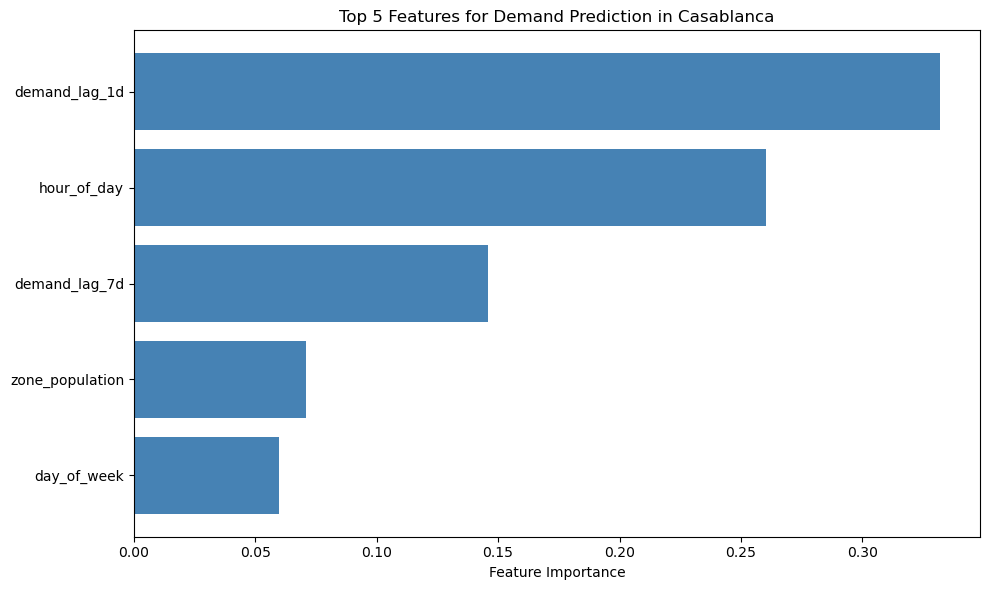

In [14]:
import matplotlib.pyplot as plt

features = ["demand_lag_1d", "hour_of_day", "demand_lag_7d", "zone_population", "day_of_week"]
importances = [0.3319, 0.2603, 0.1457, 0.0708, 0.0596]

plt.figure(figsize=(10, 6))
plt.barh(features, importances, color='steelblue')
plt.xlabel('Feature Importance')
plt.title('Top 5 Features for Demand Prediction in Casablanca')
plt.gca().invert_yaxis()
plt.tight_layout()
plt.savefig('/tmp/feature_importance.png')
print("Feature importance chart saved")

with open('/tmp/feature_importance.png', 'rb') as f:
    s3.upload_fileobj(f, 'curated', 'metrics/feature_importance.png')
print("Chart uploaded to MinIO")

In [16]:
from pyspark.sql import functions as F
from pyspark.sql.types import DoubleType

comparison_by_zone = predictions.groupBy("zone_id").agg(
    F.sqrt(F.avg(F.pow(F.col("nb_trips") - F.col("prediction"), 2))).alias("model_rmse"),
    F.sqrt(F.avg(F.pow(F.col("nb_trips") - F.col("demand_lag_7d"), 2))).alias("baseline_rmse"),
    F.count("*").alias("sample_count")
).orderBy("zone_id")

comparison_by_zone = comparison_by_zone.filter(
    F.col("baseline_rmse") > 0.01
)

comparison_by_zone_with_improvement = comparison_by_zone.withColumn(
    "improvement",
    F.when(F.col("baseline_rmse") > 0, 
           (F.col("baseline_rmse") - F.col("model_rmse")) / F.col("baseline_rmse") * 100)
    .otherwise(0)
)

print("Comparison by zone (corrected):")
comparison_by_zone_with_improvement.show(16)

comparison_pd = comparison_by_zone_with_improvement.toPandas()
print("\nZone comparison table:")
print(comparison_pd[['zone_id', 'model_rmse', 'baseline_rmse', 'improvement', 'sample_count']].to_string(index=False))

Comparison by zone (corrected):
+-------+------------------+-------------------+------------+-------------------+
|zone_id|        model_rmse|      baseline_rmse|sample_count|        improvement|
+-------+------------------+-------------------+------------+-------------------+
|      0| 317.5330158532442| 1084.3104502596907|         118|  70.71567319330036|
|      1|12.279389597485412| 15.065412927187447|         120| 18.492844126922684|
|      2| 93.81442544486623| 219.96710191736838|         135|  57.35070170624513|
|      3| 256.7522285931805|  645.0010546845778|         147|  60.19351802165052|
|      6| 30.22199942582485|  54.06522552538842|         144|  44.10085386283473|
|      7|116.04671574352402|  270.4905404082204|         151|  57.09768054424823|
|      9| 8.474811844409412|   9.20038362371534|         153|   7.88632092944102|
|     10|10.168297871724135|0.22360679774997896|          20| -4447.401051328321|
|     11|   337.38377460259|  845.7534484247687|         134| 60.1